In [6]:
!wget -q https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz
!tar -xzf aclImdb_v1.tar.gz
!ls aclImdb

imdbEr.txt  imdb.vocab	README	test  train


In [8]:
!pip install -q -U datasets
from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")
train_df = imdb["train"].to_pandas().rename(columns={"text": "review"})
test_df = imdb["test"].to_pandas().rename(columns={"text": "review"})

print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Label meaning: 0 = negative, 1 = positive")
train_df.head()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 9.0 MB/s eta 0:00:00


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

...

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Train: (25000, 2) | Test: (25000, 2)
Label meaning: 0 = negative, 1 = positive


,review,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [9]:
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_files
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)

In [10]:
train_raw = load_files("aclImdb/train", categories=["neg", "pos"],
                       encoding="utf-8", shuffle=True, random_state=42)
test_raw = load_files("aclImdb/test", categories=["neg", "pos"],
                      encoding="utf-8", shuffle=True, random_state=42)

train_df = pd.DataFrame({"review": train_raw.data, "label": train_raw.target})
test_df = pd.DataFrame({"review": test_raw.data, "label": test_raw.target})

print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Label meaning: 0 = negative, 1 = positive")
train_df.head()

Train: (25000, 2) | Test: (25000, 2)
Label meaning: 0 = negative, 1 = positive


,review,label
0,"Silent Night, Deadly Night 5 is the very last ...",0
1,The idea ia a very short film with a lot of in...,1
2,"For me, this movie just seemed to fall on its ...",0
3,Was this based on a comic-book? A video-game? ...,1
4,Caution: May contain spoilers...<br /><br />I'...,1


label
0    12500
1    12500
Name: count, dtype: int64


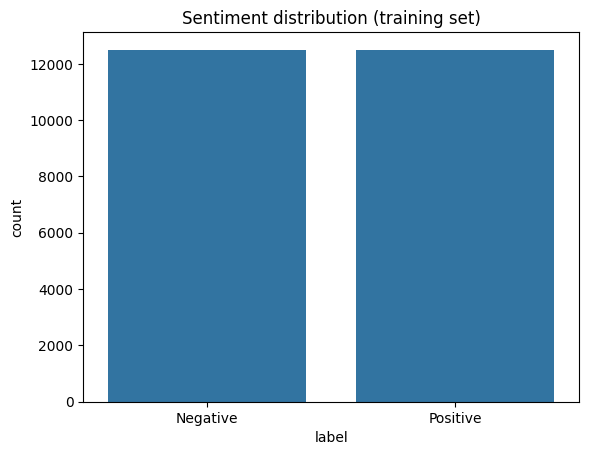

         count       mean         std   min    25%    50%    75%     max
label                                                                   
0      12500.0  230.86784  166.663126  10.0  128.0  174.0  278.0  1522.0
1      12500.0  236.70656  180.485743  12.0  125.0  174.0  291.0  2470.0


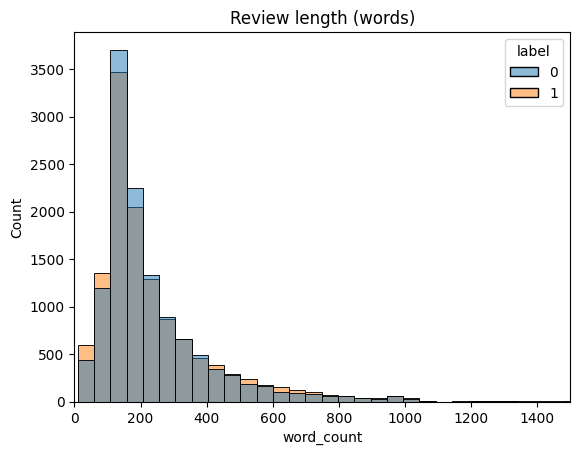

Silent Night, Deadly Night 5 is the very last of the series, and like part 4, it's unrelated to the first three except by title and the fact that it's a Christmas-themed horror flick.<br /><br />Except to the oblivious, there's some obvious things going on here...Mickey Rooney plays a toymaker named Joe Petto and his creepy son's name is Pino. Ring a bell, anyone? Now, a little boy named Derek hea


In [11]:
print(train_df["label"].value_counts())

sns.countplot(x="label", data=train_df)
plt.xticks([0, 1], ["Negative", "Positive"])
plt.title("Sentiment distribution (training set)")
plt.show()

train_df["word_count"] = train_df["review"].apply(lambda t: len(t.split()))
print(train_df.groupby("label")["word_count"].describe())

sns.histplot(data=train_df, x="word_count", hue="label", bins=50)
plt.xlim(0, 1500)
plt.title("Review length (words)")
plt.show()

print(train_df["review"].iloc[0][:400])

In [12]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_df["clean"] = train_df["review"].apply(clean_text)
test_df["clean"] = test_df["review"].apply(clean_text)

print("BEFORE:", train_df["review"].iloc[0][:200])
print("AFTER :", train_df["clean"].iloc[0][:200])

BEFORE: Silent Night, Deadly Night 5 is the very last of the series, and like part 4, it's unrelated to the first three except by title and the fact that it's a Christmas-themed horror flick.<br /><br />Excep
AFTER : silent night deadly night is the very last of the series and like part it's unrelated to the first three except by title and the fact that it's a christmas themed horror flick except to the oblivious 


In [13]:
X_train_text = train_df["clean"]
y_train = train_df["label"]
X_test_text = test_df["clean"]
y_test = test_df["label"]

In [15]:
vectorizers = {
    "Bag of Words": CountVectorizer(max_features=20000),
    "TF-IDF (single words)": TfidfVectorizer(max_features=20000),
    "TF-IDF (words + pairs)": TfidfVectorizer(max_features=50000, ngram_range=(1, 2)),
}

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
}

In [16]:
results = []
fitted = {}
test_features = {}

for vec_name, vec in vectorizers.items():
    print(f"Vectorizing with: {vec_name} ...")
    X_train_vec = vec.fit_transform(X_train_text)
    X_test_vec = vec.transform(X_test_text)
    test_features[vec_name] = X_test_vec

    for model_name, model in models.items():
        start = time.time()
        model.fit(X_train_vec, y_train)
        preds = model.predict(X_test_vec)
        seconds = time.time() - start

        results.append({
            "Vectorizer": vec_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, preds),
            "F1 score": f1_score(y_test, preds),
            "Train time (s)": round(seconds, 1),
        })
        fitted[(vec_name, model_name)] = (vec, model, preds)
        print(f"   {model_name} done")

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
print(results_df.round(4).to_string(index=False))

Vectorizing with: Bag of Words ...
   Naive Bayes done
   Logistic Regression done


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


   Linear SVM done
Vectorizing with: TF-IDF (single words) ...
   Naive Bayes done
   Logistic Regression done
   Linear SVM done
Vectorizing with: TF-IDF (words + pairs) ...
   Naive Bayes done
   Logistic Regression done
   Linear SVM done
            Vectorizer               Model  Accuracy  F1 score  Train time (s)
TF-IDF (words + pairs)          Linear SVM    0.8950    0.8946             1.2
TF-IDF (words + pairs) Logistic Regression    0.8944    0.8947             1.9
 TF-IDF (single words) Logistic Regression    0.8839    0.8839             1.6
 TF-IDF (single words)          Linear SVM    0.8752    0.8738             1.5
TF-IDF (words + pairs)         Naive Bayes    0.8689    0.8662             0.1
          Bag of Words Logistic Regression    0.8626    0.8612            27.1
          Bag of Words          Linear SVM    0.8386    0.8363            93.3
 TF-IDF (single words)         Naive Bayes    0.8344    0.8257             0.0
          Bag of Words         Naive Bayes    0

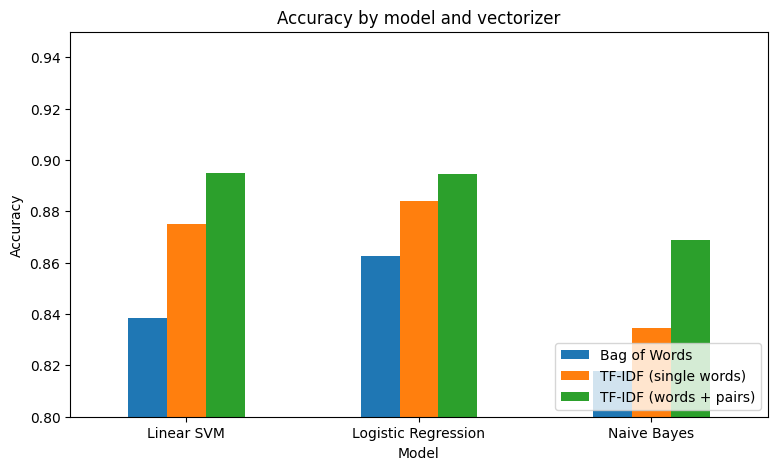

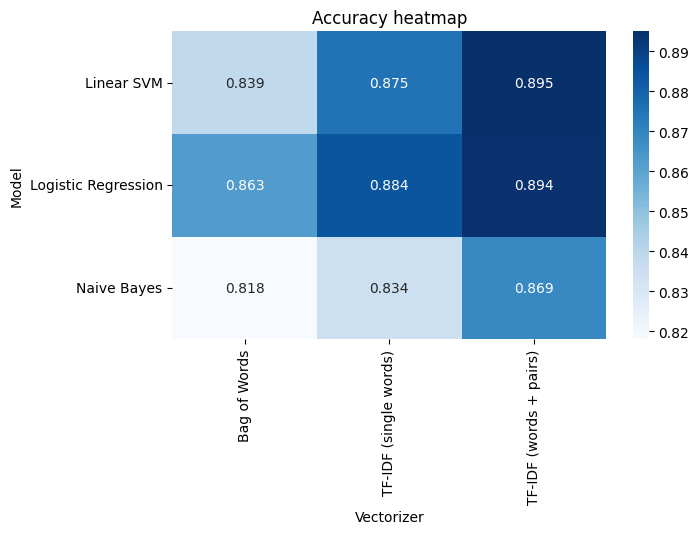

In [18]:
pivot = results_df.pivot(index="Model", columns="Vectorizer", values="Accuracy")

pivot.plot(kind="bar", figsize=(9, 5))
plt.title("Accuracy by model and vectorizer")
plt.ylabel("Accuracy")
plt.ylim(0.8, 0.95)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="Blues")
plt.title("Accuracy heatmap")
plt.show()

In [21]:
results = []
fitted = {}          # keep everything so we can reuse the best one later
test_features = {}   # keep each vectorized test set

for vec_name, vec in vectorizers.items():
    print(f"Vectorizing with: {vec_name} ...")
    X_train_vec = vec.fit_transform(X_train_text)   # learn vocabulary on TRAIN only
    X_test_vec = vec.transform(X_test_text)         # reuse it on test
    test_features[vec_name] = X_test_vec

    for model_name, model in models.items():
        start = time.time()
        model.fit(X_train_vec, y_train)
        preds = model.predict(X_test_vec)
        seconds = time.time() - start

        results.append({
            "Vectorizer": vec_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, preds),
            "F1 score": f1_score(y_test, preds),
            "Train time (s)": round(seconds, 1),
        })
        fitted[(vec_name, model_name)] = (vec, model, preds)
        print(f"   {model_name} done")

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
print(results_df.round(4).to_string(index=False))

Vectorizing with: Bag of Words ...
   Naive Bayes done
   Logistic Regression done


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


   Linear SVM done
Vectorizing with: TF-IDF (single words) ...
   Naive Bayes done
   Logistic Regression done
   Linear SVM done
Vectorizing with: TF-IDF (words + pairs) ...
   Naive Bayes done
   Logistic Regression done
   Linear SVM done
            Vectorizer               Model  Accuracy  F1 score  Train time (s)
TF-IDF (words + pairs)          Linear SVM    0.8950    0.8946             1.0
TF-IDF (words + pairs) Logistic Regression    0.8944    0.8947             1.7
 TF-IDF (single words) Logistic Regression    0.8839    0.8839             2.5
 TF-IDF (single words)          Linear SVM    0.8752    0.8738             2.2
TF-IDF (words + pairs)         Naive Bayes    0.8689    0.8662             0.1
          Bag of Words Logistic Regression    0.8626    0.8612            29.0
          Bag of Words          Linear SVM    0.8386    0.8363           106.6
 TF-IDF (single words)         Naive Bayes    0.8344    0.8257             0.0
          Bag of Words         Naive Bayes    0

Best combination: ('TF-IDF (words + pairs)', 'Linear SVM')
              precision    recall  f1-score   support

    Negative     0.8918    0.8992    0.8955     12500
    Positive     0.8984    0.8909    0.8946     12500

    accuracy                         0.8950     25000
   macro avg     0.8951    0.8950    0.8950     25000
weighted avg     0.8951    0.8950    0.8950     25000



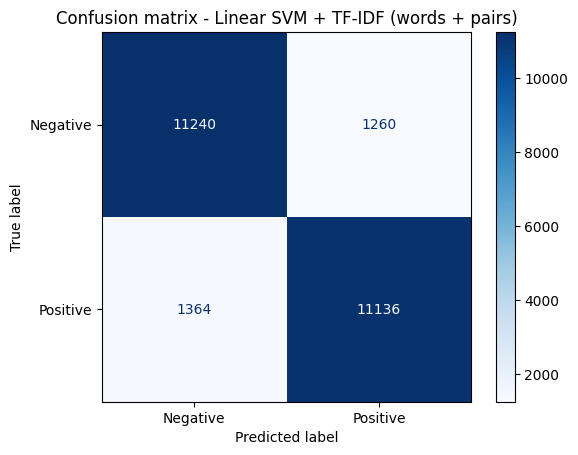

In [23]:
best = results_df.iloc[0]
best_key = (best["Vectorizer"], best["Model"])
best_vec, best_model, best_preds = fitted[best_key]

print("Best combination:", best_key)
print(classification_report(y_test, best_preds,
                            target_names=["Negative", "Positive"], digits=4))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_preds,
    display_labels=["Negative", "Positive"], cmap="Blues"
)
plt.title(f"Confusion matrix - {best_key[1]} + {best_key[0]}")
plt.show()

In [24]:
lr_vec, lr_model, _ = fitted[("TF-IDF (words + pairs)", "Logistic Regression")]
words = np.array(lr_vec.get_feature_names_out())
coefs = lr_model.coef_[0]

top_positive = words[np.argsort(coefs)[-15:]][::-1]
top_negative = words[np.argsort(coefs)[:15]]

print("Most POSITIVE words/phrases:", list(top_positive))
print("Most NEGATIVE words/phrases:", list(top_negative))

Most POSITIVE words/phrases: ['great', 'excellent', 'wonderful', 'perfect', 'best', 'the best', 'amazing', 'fun', 'and', 'love', 'well', 'loved', 'today', 'favorite', 'brilliant']
Most NEGATIVE words/phrases: ['bad', 'worst', 'awful', 'the worst', 'boring', 'poor', 'waste', 'no', 'terrible', 'nothing', 'worse', 'dull', 'stupid', 'horrible', 'poorly']


In [25]:
def predict_sentiment(review, low=0.35, high=0.65):
    cleaned = clean_text(review)
    features = lr_vec.transform([cleaned])
    prob_positive = lr_model.predict_proba(features)[0][1]

    if prob_positive >= high:
        label = "Positive"
    elif prob_positive <= low:
        label = "Negative"
    else:
        label = "Neutral"
    return label, round(prob_positive, 3)

my_reviews = [
    "An absolutely brilliant film, I loved every minute of it.",
    "Terrible plot, awful acting, a complete waste of time.",
    "It was okay. Some good scenes, some boring ones.",
    "Not bad, but I wouldn't watch it again.",
]

for r in my_reviews:
    label, prob = predict_sentiment(r)
    print(f"{label:9} (P(positive) = {prob})  ->  {r}")

Positive  (P(positive) = 0.831)  ->  An absolutely brilliant film, I loved every minute of it.
Negative  (P(positive) = 0.001)  ->  Terrible plot, awful acting, a complete waste of time.
Negative  (P(positive) = 0.117)  ->  It was okay. Some good scenes, some boring ones.
Negative  (P(positive) = 0.348)  ->  Not bad, but I wouldn't watch it again.
